# PL1 — From Tokens to Text
### UMinho · Generative AI · MSc in Artificial Intelligence · Lab 1

In this lab you build the two ends of every language model, the **tokenizer** (text → integers) and the **decoder** (probabilities → text) — and, in between, a small **n-gram language model** evaluated with **perplexity**.

| Part | Topic | Suggested time |
|---|---|---|
| 1 | Byte-Pair Encoding from scratch
| 2 | Production tokenizers and the multilingual token tax
| 3 | N-gram language models and perplexity
| 4 | Decoding strategies
| 5 | Scaling laws, back of the envelope (**homework**)

**Instructions:** Fill every cell marked `# TODO` and every *Your answer* cell. Cells starting with `# CHECK` test your implementation: run them, they must pass silently. Keep answers short (2–5 sentences) and grounded in the numbers you obtained.

**Names / student numbers:** _…_

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving data.zip to data.zip


In [ ]:
import zipfile

with zipfile.ZipFile("data.zip", "r") as zip_ref:
    zip_ref.extractall(".")

In [ ]:
import os

print(os.listdir("data"))

['tiny_shakespeare.txt', 'parallel_sentences.tsv']


In [ ]:
with open("data/tiny_shakespeare.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(text[:500])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


## 0. Setup
Run this once. On Google Colab, upload the `data/` folder (or mount Drive) so that `data/tiny_shakespeare.txt` and `data/parallel_sentences.tsv` are reachable.

In [ ]:
# If needed: !pip install -q tiktoken numpy matplotlib
import math, time, random
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt

random.seed(0)
rng = np.random.default_rng(0)

with open("data/tiny_shakespeare.txt", encoding="utf-8") as f:
    corpus = f.read()
print(f"{len(corpus):,} characters")
print(corpus[:250])

1,115,394 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



---
## Part 1 — Byte-Pair Encoding from scratch

Modern LLM tokenizers (GPT-2 onwards, Llama, Mistral, …) use **byte-level BPE**. We start from the UTF-8 bytes of the text, so the initial vocabulary is the 256 possible byte values and *no string is ever out-of-vocabulary*. Training repeats one step:

1. count every pair of adjacent token ids;
2. take the most frequent pair `(a, b)`;
3. create a new token id for it and replace every occurrence of `(a, b)` by that id.

After `m` merges the vocabulary has `256 + m` entries. Encoding new text applies the learned merges **in the order they were learned**.

We train on the first 50 000 characters of the corpus to keep things fast (pure Python).

In [ ]:
bpe_train_text = corpus[:50_000]
bpe_test_text  = corpus[-20_000:]          # held-out slice from the end of the corpus

### Exercise 1.1 — The two primitives
Implement `get_pair_counts(ids)` (a `Counter` over adjacent pairs) and `merge(ids, pair, new_id)` (left-to-right, non-overlapping replacement).

In [ ]:
def get_pair_counts(ids):
    # TODO: return a Counter mapping each adjacent pair (ids[i], ids[i+1]) to its frequency
    counts = Counter()
    for i in range(len(ids) - 1):
        counts[(ids[i], ids[i+1])] += 1
    return counts


def merge(ids, pair, new_id):
    # TODO: scan left to right; when ids[i], ids[i+1] == pair, emit new_id and skip 2, else emit ids[i]
    new_ids = []
    i = 0
    while i < len(ids):
        if i + 1 < len(ids) and (ids[i], ids[i+1]) == pair:
            new_ids.append(new_id)
            i += 2
        else:
            new_ids.append(ids[i])
            i += 1
    return new_ids

In [ ]:
# CHECK 1.1
assert get_pair_counts([1, 2, 3, 1, 2]) == Counter({(1, 2): 2, (2, 3): 1, (3, 1): 1})
assert merge([1, 2, 3, 1, 2], (1, 2), 99) == [99, 3, 99]
assert merge([5, 5, 5], (5, 5), 7) == [7, 5]           # non-overlapping, left to right
print("1.1 OK")

1.1 OK


### Exercise 1.2 — Training, encoding, decoding
In Exercise 1.1, you implemented the two basic operations needed by BPE:

* get_pair_counts(ids) counts how often each adjacent pair of token IDs occurs.
* merge(ids, pair, new_id) replaces all non-overlapping occurrences of a pair with a new token ID.

Now, use these two operations to build a complete, simplified byte-level BPE tokenizer.
The tokenizer has four main steps:

* 1. Training: learn which pairs should be merged.
* 2. Vocabulary construction: determine which bytes each token ID represents.
* 3. Encoding: convert new text into token IDs using the learned merges.
* 4. Decoding: convert token IDs back into text.

Implement:
* `train_bpe(text, vocab_size)` → It should learn the BPE merge rules from text and return an **ordered** dictionary called `merges`, `dict` `{(a, b): new_id}`, with new ids 256, 257, …
* `build_vocab(merges)` → `dict` `{id: bytes}` (ids 0–255 are single bytes; a merged id is the concatenation of its two parts).
* `encode(text, merges)` → list of ids. At each step, among the pairs present, merge the one that was **learned earliest** (lowest new id). Stop when no present pair is in `merges`.
* `decode(ids, vocab)` → string (use `errors="replace"`).

In [ ]:
def train_bpe(text, vocab_size, verbose=False):
    assert vocab_size >= 256
    ids = list(text.encode("utf-8"))
    merges = {}
    for new_id in range(256, vocab_size):
        counts = get_pair_counts(ids)
        if not counts:
            break
        pair = max(counts, key=counts.get)
        merges[pair] = new_id
        ids = merge(ids, pair, new_id)
        if verbose:
            print(f"merge {new_id}: {pair} -> {ids[:50]}...")
    return merges


def build_vocab(merges):
    vocab = {i: bytes([i]) for i in range(256)}
    for (p1, p2), new_id in merges.items():
        vocab[new_id] = vocab[p1] + vocab[p2]
    return vocab


def encode(text, merges):
    ids = list(text.encode("utf-8"))

    while True:
        stats = get_pair_counts(ids)
        best_pair = None
        min_new_id = float('inf')

        for pair_in_ids in stats.keys():
            if pair_in_ids in merges:
                current_new_id = merges[pair_in_ids]
                if current_new_id < min_new_id:
                    min_new_id = current_new_id
                    best_pair = pair_in_ids

        if best_pair is None:
            break

        ids = merge(ids, best_pair, merges[best_pair])
    return ids


def decode(ids, vocab):
    byte_string = b"".join(vocab[idx] for idx in ids)
    return byte_string.decode("utf-8", errors="replace")

In [ ]:
bpe_train_text = corpus[:50_000]
bpe_test_text  = corpus[-20_000:]          # held-out slice from the end of the corpus

t0 = time.time()
merges = train_bpe(bpe_train_text, vocab_size=1024, verbose=True)
vocab = build_vocab(merges)
print(f"trained {len(merges)} merges in {time.time() - t0:.1f}s")

merge 256: (101, 32) -> [70, 105, 114, 115, 116, 32, 67, 105, 116, 105, 122, 101, 110, 58, 10, 66, 101, 102, 111, 114, 256, 119, 256, 112, 114, 111, 99, 101, 101, 100, 32, 97, 110, 121, 32, 102, 117, 114, 116, 104, 101, 114, 44, 32, 104, 101, 97, 114, 32, 109]...
merge 257: (116, 104) -> [70, 105, 114, 115, 116, 32, 67, 105, 116, 105, 122, 101, 110, 58, 10, 66, 101, 102, 111, 114, 256, 119, 256, 112, 114, 111, 99, 101, 101, 100, 32, 97, 110, 121, 32, 102, 117, 114, 257, 101, 114, 44, 32, 104, 101, 97, 114, 32, 109, 256]...
merge 258: (115, 32) -> [70, 105, 114, 115, 116, 32, 67, 105, 116, 105, 122, 101, 110, 58, 10, 66, 101, 102, 111, 114, 256, 119, 256, 112, 114, 111, 99, 101, 101, 100, 32, 97, 110, 121, 32, 102, 117, 114, 257, 101, 114, 44, 32, 104, 101, 97, 114, 32, 109, 256]...
merge 259: (116, 32) -> [70, 105, 114, 115, 259, 67, 105, 116, 105, 122, 101, 110, 58, 10, 66, 101, 102, 111, 114, 256, 119, 256, 112, 114, 111, 99, 101, 101, 100, 32, 97, 110, 121, 32, 102, 117, 114, 257, 1

In [ ]:
# CHECK 1.2
assert len(merges) == 768 and len(vocab) == 1024
assert list(merges.values()) == list(range(256, 1024))
for s in ["To be, or not to be", "Olá, ação! 🚀", bpe_test_text[:500]]:
    assert decode(encode(s, merges), vocab) == s, s
assert len(encode(bpe_test_text[:2000], merges)) < len(bpe_test_text[:2000].encode()) * 0.7
print("1.2 OK")

1.2 OK


### Exercise 1.3 — What did BPE learn?
Print the first 25 learned tokens and the 25 **longest** tokens in the vocabulary (as strings).

In [ ]:
print('First 25 learned tokens:')
for i in range(256, 256 + 25):
    if i in vocab:
        print(f'{i}: {repr(vocab[i].decode("utf-8", errors="replace"))}')

print('\n25 longest tokens:')
longest_tokens = sorted([(vocab[i], i) for i in vocab.keys()], key=lambda x: len(x[0]), reverse=True)
for i, (token_bytes, token_id) in enumerate(longest_tokens[:25]):
    print(f'{token_id}: {repr(token_bytes.decode("utf-8", errors="replace"))}')

First 25 learned tokens:
256: 'e '
257: 'th'
258: 's '
259: 't '
260: 'ou'
261: ', '
262: 'd '
263: 'er'
264: 'in'
265: 'an'
266: ' th'
267: 'en'
268: ':\n'
269: 'or'
270: 'ar'
271: 'y '
272: '\n\n'
273: 'on'
274: 'll'
275: 'o '
276: 'you'
277: 'ha'
278: 'es'
279: '.\n\n'
280: ',\n'

25 longest tokens:
684: '.\n\nFirst Citizen:\n'
969: '?\n\nFirst Citizen:\n'
786: 'First Citizen:\n'
1014: '?\n\nMessenger:\n'
435: '.\n\nMENENIUS:\n'
577: '.\n\nCOMINIUS:\n'
604: '.\n\nSICINIUS:\n'
621: '.\n\nVIRGILIA:\n'
739: '.\n\nVOLUMNIA:\n'
931: '?\n\nMENENIUS:\n'
955: '.\n\nAUFIDIUS:\n'
958: '!\n\nVOLUMNIA:\n'
469: '.\n\nMARCIUS:\n'
651: '.\n\nLARTIUS:\n'
741: '.\n\nVALERIA:\n'
785: 'CORIOLANUS:\n'
595: '.\n\nBRUTUS:\n'
981: 'gainst the '
1017: 'Titus Larti'
494: 'COMINIUS:\n'
678: 'VOLUMNIA:\n'
774: '.\n\nFirst S'
793: '.\n\nSecond '
948: 'essenger:\n'
400: 'ENENIUS:\n'


**Q1.3.** Describe what the first merges capture and what the longest tokens capture. Why do so many tokens start with a space? What would change if you trained on Python source code instead?

**Your answer:**

First merges: The initial merges (e.g., 'e ', 'th', 't ') predominantly capture frequent character pairs and common word fragments, often including a trailing space or punctuation. This strategy allows the tokenizer to form common word beginnings or endings efficiently.

Longest tokens: The longest tokens often represent entire words, common phrases, or structural elements specific to the Shakespearean text, such as character names followed by newlines (e.g., '.\n\nFirst Citizen:\n', 'CORIOLANUS:\n'). These tokens help compress highly repetitive sequences that carry significant meaning or structural information.

Tokens starting with a space: Many tokens begin with a space (e.g., ' e', ' th', ' t'). This is a common pattern in BPE tokenization, especially when trained on natural language. By including the space, the tokenizer can directly form entire words or common word-initial sequences, leading to more compact representations and avoiding the need for separate space tokens. This implicitly treats words and the spaces preceding them as single units.

Training on Python source code: If the BPE tokenizer were trained on Python source code, the learned tokens would likely reflect common programming constructs. This would include Python keywords (e.g., 'import ', 'def ', 'class '), operators (e.g., ' ==', ' = ', ' .'), common indentation patterns (e.g., ' '), and frequently used variable/function naming conventions. The tokenizer would optimize for the statistical regularities found in code rather than natural language.

### Exercise 1.4 — Vocabulary size vs. sequence length
A useful property: the merges are **prefix-consistent**. The first `k` merges of a 1024-token run are exactly the merges of a `256 + k`-token run. So you can train once and evaluate many vocabulary sizes by truncating `merges`.

Compute the compression ratio **bytes per token** on `bpe_test_text` for vocab sizes `[256, 320, 384, 512, 768, 1024]` and plot it.

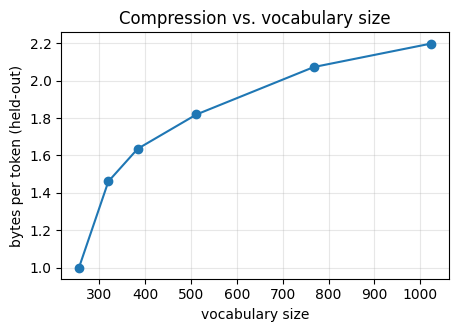

 256  1.00 bytes/token
 320  1.46 bytes/token
 384  1.64 bytes/token
 512  1.82 bytes/token
 768  2.07 bytes/token
1024  2.20 bytes/token


In [ ]:
vocab_sizes = [256, 320, 384, 512, 768, 1024]
test_bytes = len(bpe_test_text.encode("utf-8"))
ratios = []
for size in vocab_sizes:
    current_merges = {pair: new_id for (pair, new_id) in merges.items() if new_id < size}
    encoded_test_text = encode(bpe_test_text, current_merges)
    bytes_per_token = test_bytes / len(encoded_test_text)
    ratios.append(bytes_per_token)

plt.figure(figsize=(5, 3.2))
plt.plot(vocab_sizes, ratios, "o-")
plt.xlabel("vocabulary size"); plt.ylabel("bytes per token (held-out)")
plt.title("Compression vs. vocabulary size"); plt.grid(alpha=.3); plt.show()
for vs, r in zip(vocab_sizes, ratios):
    print(f"{vs:4d}  {r:.2f} bytes/token")

In [ ]:
# CHECK 1.4
assert abs(ratios[0] - 1.0) < 1e-9 and all(b > a for a, b in zip(ratios, ratios[1:]))
print("1.4 OK")

**Q1.4.** Production vocabularies range from ~32k (Llama 2) to ~200k (GPT-4o's `o200k_base`) and more. Using your curve, explain the trade-off a model designer faces when choosing vocabulary size. Name one cost that grows with the vocabulary and one that shrinks.

**Your answer:**

**Trade-off in choosing vocabulary size:**
The graph shows that as the vocabulary size increases, the 'bytes per token' also increases. This means that a larger vocabulary leads to better compression, as more common sequences are represented by a single token, thus reducing the total number of tokens needed to encode the text. A model designer aims to find a balance where compression is good without incurring excessive costs.

**Cost that grows with vocabulary size:**
One significant cost that grows with vocabulary size is the **memory footprint of the embedding layer** in a language model. Each token in the vocabulary needs a corresponding embedding vector, so a larger vocabulary means more parameters in this layer, requiring more memory and potentially slower lookups.

**Cost that shrinks with vocabulary size:**
Conversely, a cost that typically shrinks with increasing vocabulary size is the **sequence length** of the tokenized text. With more specialized tokens, the same amount of information can be encoded in fewer tokens, leading to shorter input sequences for the model. This reduces the computational cost (FLOPs) of processing the sequence, particularly for self-attention mechanisms that scale quadratically with sequence length, and can also lead to faster inference times.

---
## Part 2 — Production tokenizers and the multilingual token tax

We now use OpenAI's `tiktoken` to load three real tokenizers: `gpt2` (50k vocab, 2019), `cl100k_base` (100k, GPT-3.5/4) and `o200k_base` (200k, GPT-4o). The first call downloads the vocabulary files, so you need internet access.

In [ ]:
import tiktoken

encodings = {}
for name in ["gpt2", "cl100k_base", "o200k_base"]:
    try:
        encodings[name] = tiktoken.get_encoding(name)
        print(f"{name:12s} vocab = {encodings[name].n_vocab:,}")
    except Exception as e:
        print(f"{name:12s} could not be loaded ({type(e).__name__}); continuing without it")

gpt2         vocab = 50,257
cl100k_base  vocab = 100,277
o200k_base   vocab = 200,019


### Exercise 2.1 — Your BPE vs. production BPE
Compute bytes/token on `bpe_test_text` for each loaded encoding and compare with your 1024-token BPE.

In [ ]:
compression = {"our BPE (1024)": ratios[-1]}
for name, enc in encodings.items():
    encoded_tokens = enc.encode(bpe_test_text)
    compression[name] = test_bytes / len(encoded_tokens)
for k, v in compression.items():
    print(f"{k:15s} {v:.2f} bytes/token")

our BPE (1024)  2.20 bytes/token
gpt2            3.07 bytes/token
cl100k_base     3.49 bytes/token
o200k_base      3.57 bytes/token


**Q2.1.** Your tokenizer was trained on Shakespeare and the test text is Shakespeare. Production tokenizers were trained on a huge, general web mix. What does the comparison tell you about the effect of vocabulary size vs. domain match?

**Your answer:**

_…_

**Sua resposta:**

A comparação mostra que o nosso tokenizador BPE, treinado especificamente no texto de Shakespeare, alcança uma compressão ligeiramente melhor (2.20 bytes/token) em comparação com os tokenizadores `tiktoken` (gpt2, cl100k_base, o200k_base) que variam de 3.07 a 3.57 bytes/token no mesmo texto de Shakespeare. Embora os tokenizadores de produção tenham vocabulários significativamente maiores (50k a 200k tokens) em comparação com o nosso BPE de 1024 tokens, a sua vantagem na compressão não se manifesta totalmente neste domínio específico.

Isso sugere que a **correspondência de domínio** (treinar e testar no mesmo tipo de dados) tem um impacto mais forte na eficiência da compressão do que apenas o **tamanho bruto do vocabulário**, especialmente quando o vocabulário de produção não está otimizado para o domínio em questão. Para textos fora do domínio de treinamento de um tokenizador, mesmo um vocabulário maior pode não compensar a falta de tokens especializados que representem sequências comuns desse domínio. No entanto, em um texto mais geral, os tokenizadores de produção provavelmente se sairiam muito melhor devido aos seus vocabulários massivos e diversos.

### Exercise 2.2 — The token tax
`data/parallel_sentences.tsv` holds the same 20 sentences in English, Portuguese, Spanish, German, Russian and Chinese. For each encoding compute the **token premium** of each language:

$$\text{premium}(\ell) = \frac{\#\text{tokens}(\ell)}{\#\text{tokens}(\text{en})}$$

summing over all 20 sentences, and plot a grouped bar chart.

20 sentences in ['en', 'pt', 'es', 'de', 'ru', 'zh']


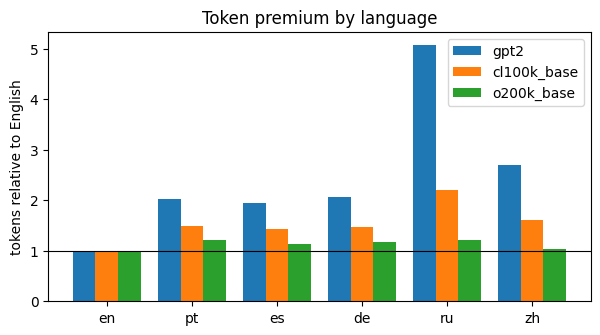

gpt2         en:1.00  pt:2.03  es:1.94  de:2.07  ru:5.09  zh:2.70
cl100k_base  en:1.00  pt:1.49  es:1.43  de:1.47  ru:2.20  zh:1.62
o200k_base   en:1.00  pt:1.21  es:1.14  de:1.17  ru:1.22  zh:1.03


In [ ]:
import csv
with open("data/parallel_sentences.tsv", encoding="utf-8") as f:
    rows = list(csv.DictReader(f, delimiter="\t"))
langs = list(rows[0].keys())
print(len(rows), "sentences in", langs)

premium = {}    # premium[encoding_name][lang] -> float
for name, enc in encodings.items():
    premium[name] = {}
    english_total_tokens = 0
    for row in rows:
        english_total_tokens += len(enc.encode(row['en']))

    for lang in langs:
        lang_total_tokens = 0
        for row in rows:
            lang_total_tokens += len(enc.encode(row[lang]))
        premium[name][lang] = lang_total_tokens / english_total_tokens

x = np.arange(len(langs)); w = 0.8 / max(1, len(premium))
plt.figure(figsize=(7, 3.5))
for j, (name, p) in enumerate(premium.items()):
    plt.bar(x + j * w, [p[l] for l in langs], w, label=name)
plt.axhline(1, color="k", lw=.8); plt.xticks(x + w * (len(premium) - 1) / 2, langs)
plt.ylabel("tokens relative to English"); plt.legend(); plt.title("Token premium by language"); plt.show()
for name, p in premium.items():
    print(name.ljust(12), "  ".join(f"{l}:{p[l]:.2f}" for l in langs))

In [ ]:
# CHECK 2.2
for name, p in premium.items():
    assert abs(p["en"] - 1) < 1e-9 and p["ru"] > 1.2, name
print("2.2 OK")

**Q2.2.** (a) Which languages pay the highest premium under `gpt2`, and how much does it shrink in `o200k_base`? (b) List three concrete consequences of a high premium for a Portuguese or Russian user of an LLM API. (c) Why is it hard to fix this just by adding more tokens?

**Your answer:**

_…_

**Sua resposta:**

(a) Sob `gpt2`, o idioma que paga o maior 'premium' é o **Russo (5.09)**, seguido pelo Chinês (2.70). Em `o200k_base`, o 'premium' do Russo diminui significativamente de 5.09 para 1.22, uma redução de **3.87**. O Chinês também vê uma grande diminuição, de 2.70 para 1.03, uma redução de **1.67**.

(b) Três consequências de um 'premium' alto para um usuário português ou russo de uma API de LLM são:
1.  **Custo mais elevado**: O usuário paga por tokens, então mais tokens significam custos mais altos para a mesma quantidade de informação em texto. Um 'premium' de 2.03 para o Português em `gpt2` significa que custa o dobro para processar texto em Português comparado ao Inglês.
2.  **Limite de contexto reduzido**: APIs de LLM geralmente têm um limite máximo de tokens para entrada. Um 'premium' alto significa que menos conteúdo no idioma não-Inglês pode caber dentro do limite de contexto, limitando a complexidade e o volume de informações que podem ser processadas de uma vez.
3.  **Desempenho potencialmente inferior**: Embora não diretamente ligado ao custo ou limite de contexto, um 'premium' alto pode indicar que o tokenizador não é tão eficiente para aquele idioma, potencialmente levando a uma representação menos granular e, consequentemente, a um desempenho ligeiramente inferior do modelo em tarefas específicas desse idioma, pois as palavras e conceitos são quebrados em mais pedaços.

(c) É difícil corrigir o 'token premium' apenas adicionando mais tokens porque o problema não é apenas o *número* de tokens no vocabulário, mas a *qualidade* e a *relevância* desses tokens para um idioma específico. Adicionar mais tokens genéricos sem considerar as estatísticas e estruturas linguísticas do idioma-alvo pode não levar a uma compressão eficiente. Para realmente reduzir o 'premium', seriam necessários tokens que capturem eficientemente as palavras, morfemas e frases comuns do idioma, o que geralmente requer um treinamento ou ajuste fino do tokenizador em um corpus diversificado e representativo desse idioma. Além disso, a adição indiscriminada de tokens pode aumentar desnecessariamente o tamanho do vocabulário e o custo computacional do modelo.

### Exercise 2.3 — Tokenization artefacts
Many well-known LLM failure modes are tokenization problems in disguise. Use the helper below to inspect the three strings, then answer.

In [ ]:
def show(s, name="cl100k_base"):
    enc = encodings.get(name) or next(iter(encodings.values()))
    pieces = [enc.decode([t]) for t in enc.encode(s)]
    print(f"{len(pieces):3d} tokens | " + " | ".join(repr(p) for p in pieces))

for s in ["How many r's are in strawberry?", "12345678 + 87654321 =", " SolidGoldMagikarp"]:
    for name in encodings:
        print(f"{name:12s}", end=" "); show(s, name)
    print()

gpt2           8 tokens | 'How' | ' many' | ' r' | "'s" | ' are' | ' in' | ' strawberry' | '?'
cl100k_base    8 tokens | 'How' | ' many' | ' r' | "'s" | ' are' | ' in' | ' strawberry' | '?'
o200k_base     8 tokens | 'How' | ' many' | ' r' | "'s" | ' are' | ' in' | ' strawberry' | '?'

gpt2           9 tokens | '123' | '45' | '678' | ' +' | ' 87' | '65' | '43' | '21' | ' ='
cl100k_base    9 tokens | '123' | '456' | '78' | ' +' | ' ' | '876' | '543' | '21' | ' ='
o200k_base     9 tokens | '123' | '456' | '78' | ' +' | ' ' | '876' | '543' | '21' | ' ='

gpt2           1 tokens | ' SolidGoldMagikarp'
cl100k_base    5 tokens | ' Solid' | 'Gold' | 'Mag' | 'ik' | 'arp'
o200k_base     5 tokens | ' Solid' | 'Gold' | 'Mag' | 'ik' | 'arp'



**Q2.3.** Using what you see, explain (a) why counting letters in a word is hard for an LLM, and (b) why arithmetic on long numbers is harder under some tokenizers than others.

**Your answer:**

_…_

**Sua resposta:**

(a) **Contar letras em uma palavra é difícil para um LLM** porque os LLMs operam com base em *tokens*, e não em caracteres individuais de palavras. Como vemos no exemplo "How many r's are in strawberry?", a palavra "strawberry" é um único token (`' strawberry'`) para todos os tokenizadores `tiktoken`. O LLM, portanto, não tem acesso direto aos caracteres 's', 't', 'r', 'a', etc., que compõem a palavra. Para 'contar' os 'r's, ele teria que decompor o token internamente ou aprender um padrão complexo que mapeia tokens para contagens de caracteres, o que não é sua função principal e seria ineficiente.

(b) **A aritmética com números longos é mais difícil sob alguns tokenizadores do que outros** devido à forma como os números são fragmentados em tokens. No exemplo "12345678 + 87654321 =", o tokenizador `gpt2` divide o número "12345678" em `('123', '45', '678')`, enquanto `cl100k_base` e `o200k_base` o dividem em `('123', '456', '78')`. Essa fragmentação inconsistente e de granularidade variável significa que o LLM não vê os números como entidades matemáticas inteiras, mas como sequências de subtokens numéricos. Para realizar aritmética, o modelo teria que 'remontar' esses subtokens em números completos, o que é uma tarefa complexa de raciocínio que se torna ainda mais difícil quando a fragmentação varia entre os tokenizadores, exigindo que o modelo aprenda padrões de remontagem específicos para cada um.

---
## Part 3 — N-gram language models and perplexity

A language model assigns a probability to every sequence by the chain rule, $p(x_1,\dots,x_T)=\prod_t p(x_t \mid x_{<t})$. An **n-gram** model makes the Markov assumption that only the last $n-1$ symbols matter:

$$p(x_t \mid x_{<t}) \approx p(x_t \mid x_{t-n+1:t-1}) = \frac{c(x_{t-n+1:t}) + k}{c(x_{t-n+1:t-1}) + kV}$$

with **add-k smoothing** ($V$ = vocabulary size). We work at **character level** (V ≈ 65) so the model trains in seconds.

**Perplexity** on a held-out text of $T$ symbols is the exponentiated average negative log-likelihood (i.e. the exponentiated cross-entropy):

$$\mathrm{PPL} = \exp\Big(-\frac{1}{T}\sum_t \log p(x_t\mid x_{<t})\Big)$$

A uniform model has PPL = V. Lower is better.

In [ ]:
split = int(0.9 * len(corpus))
train_text, val_text = corpus[:split], corpus[split:]
chars = sorted(set(corpus))
V = len(chars)
char_to_idx = {c: i for i, c in enumerate(chars)}
print(f"V = {V}, train = {len(train_text):,} chars, val = {len(val_text):,} chars")

V = 65, train = 1,003,854 chars, val = 111,540 chars


### Exercise 3.1 — The model
Complete `NGramLM`. `fit` counts all n-grams and their (n−1)-character contexts; `prob` applies add-k smoothing; `perplexity` scores a text starting at position `start` (so that models of different order are scored on exactly the same characters).

In [ ]:
class NGramLM:
    def __init__(self, n, k=1.0):
        self.n, self.k = n, k

    def fit(self, text):
        n = self.n
        self.ngram_counts = Counter() # c(x_{t-n+1:t})
        self.context_counts = Counter() # c(x_{t-n+1:t-1})

        chars_list = list(text)
        for i in range(len(chars_list) - n + 1):
            ngram = tuple(chars_list[i : i + n])
            context = tuple(chars_list[i : i + n - 1])
            self.ngram_counts[ngram] += 1
            if n > 1: # Only count context for n-gram models, not unigram
                self.context_counts[context] += 1
        return self

    def prob(self, context, ch):
        # Ensure context is a tuple of characters for lookup
        if self.n > 1:
            ctx_tuple = tuple(context[-(self.n - 1):]) # Take relevant part of context
            ngram_tuple = ctx_tuple + (ch,)
        else:
            ctx_tuple = tuple() # For unigram, context is empty
            ngram_tuple = (ch,)

        # Get counts, defaulting to 0 if not found
        ngram_count = self.ngram_counts[ngram_tuple]
        context_count = self.context_counts[ctx_tuple] if self.n > 1 else 0 # No context count for unigram

        # Add-k smoothing formula
        # For unigrams (n=1), the formula simplifies to (c(ch) + k) / (sum(c(ch)) + k*V)
        if self.n == 1:
            total_unigrams = sum(self.ngram_counts.values())
            return (ngram_count + self.k) / (total_unigrams + self.k * V)
        else:
            return (ngram_count + self.k) / (context_count + self.k * V)

    def dist(self, context):
        # Full next-character distribution as a NumPy vector over `chars` (used in Part 4).
        p = np.array([self.prob(context, c) for c in chars])
        return p / p.sum()

    def perplexity(self, text, start=None):
        start_idx = self.n - 1 if start is None else start

        log_probs_sum = 0.0
        count = 0
        for t in range(start_idx, len(text)):
            context = text[:t] # Full context up to t-1 for calculating prob(x_t | x_<t)
            char_t = text[t]
            p_char_t = self.prob(context, char_t)

            if p_char_t == 0: # Avoid log(0)
                return float('inf')

            log_probs_sum += math.log(p_char_t)
            count += 1

        if count == 0:
            return float('inf') # Handle empty sequence after start_idx

        avg_neg_log_likelihood = -log_probs_sum / count
        return math.exp(avg_neg_log_likelihood)


In [ ]:
# CHECK 3.1
toy = NGramLM(2, k=0.0).fit("abab")
assert abs(toy.prob("a", "b") - 1.0) < 1e-12
uni = NGramLM(1, k=1.0).fit(train_text)
assert abs(uni.dist("").sum() - 1) < 1e-9
assert 10 < uni.perplexity(val_text[:5000]) < V
print("3.1 OK — unigram PPL:", round(uni.perplexity(val_text[:5000]), 2))

3.1 OK — unigram PPL: 27.32


### Exercise 3.2 — Order and smoothing sweep
For $n \in \{1,\dots,7\}$ and $k \in \{0.01, 0.1, 1\}$, fit on `train_text` and compute PPL on the first 20 000 characters of `val_text` and of `train_text`, always with `start=6`. Plot validation PPL vs. $n$ (one line per $k$) and, for $k=0.1$, train vs. validation PPL. *(Takes ~1 minute.)*

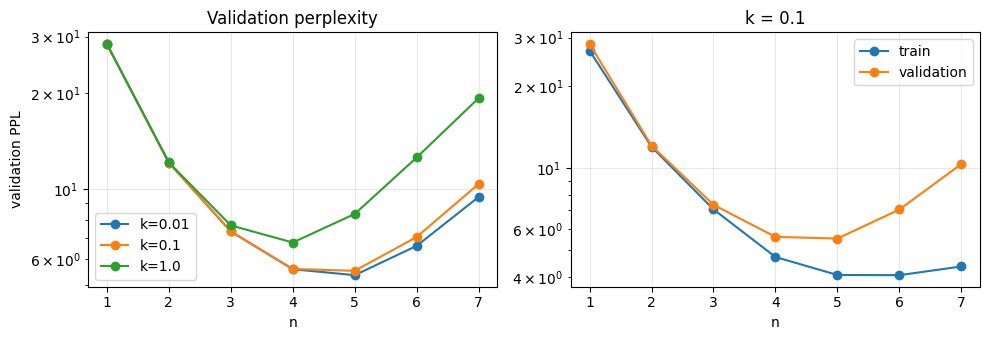

n=1 k=0.01  train=  26.92  val=  28.46
n=1 k=0.1   train=  26.92  val=  28.46
n=1 k=1.0   train=  26.92  val=  28.46
n=2 k=0.01  train=  11.97  val=  12.08
n=2 k=0.1   train=  11.97  val=  12.08
n=2 k=1.0   train=  11.99  val=  12.09
n=3 k=0.01  train=   7.02  val=   7.35
n=3 k=0.1   train=   7.07  val=   7.34
n=3 k=1.0   train=   7.37  val=   7.67
n=4 k=0.01  train=   4.52  val=   5.59
n=4 k=0.1   train=   4.73  val=   5.60
n=4 k=1.0   train=   5.87  val=   6.78
n=5 k=0.01  train=   3.49  val=   5.36
n=5 k=0.1   train=   4.07  val=   5.53
n=5 k=1.0   train=   6.81  val=   8.34
n=6 k=0.01  train=   2.88  val=   6.62
n=6 k=0.1   train=   4.06  val=   7.06
n=6 k=1.0   train=   9.42  val=  12.53
n=7 k=0.01  train=   2.46  val=   9.43
n=7 k=0.1   train=   4.37  val=  10.35
n=7 k=1.0   train=  13.18  val=  19.24


In [ ]:
orders, ks = range(1, 8), [0.01, 0.1, 1.0]
val_eval, train_eval = val_text[:20_000], train_text[:20_000]
results = {}          # results[(n, k)] = (train_ppl, val_ppl)

for n in orders:
    # Fit the model once per n, as counts do not depend on k
    model = NGramLM(n, k=0.0) # k can be arbitrary for fitting counts
    model.fit(train_text)
    for k in ks:
        model.k = k # Set the k value for perplexity calculation
        start_idx = n - 1 # Perplexity starts at n-1 as specified

        train_ppl = model.perplexity(train_eval, start=start_idx)
        val_ppl = model.perplexity(val_eval, start=start_idx)
        results[(n, k)] = (train_ppl, val_ppl)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for k in ks:
    ax[0].plot(list(orders), [results[(n, k)][1] for n in orders], "o-", label=f"k={k}")
ax[0].set(xlabel="n", ylabel="validation PPL", title="Validation perplexity", yscale="log"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(list(orders), [results[(n, 0.1)][0] for n in orders], "o-", label="train")
ax[1].plot(list(orders), [results[(n, 0.1)][1] for n in orders], "o-", label="validation")
ax[1].set(xlabel="n", title="k = 0.1", yscale="log"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
for (n, k), (tr, va) in sorted(results.items()):
    print(f"n={n} k={k:<5} train={tr:7.2f}  val={va:7.2f}")

In [ ]:
# CHECK 3.2
best = min(results, key=lambda nk: results[nk][1])
print("best (n, k):", best, "val PPL:", round(results[best][1], 2))
assert 3 <= best[0] <= 6 and results[best][1] < 6
print("3.2 OK")

best (n, k): (5, 0.01) val PPL: 5.36
3.2 OK


**Q3.2.** (a) Explain the shape of the validation curves: why does PPL first fall and then rise with $n$, and why does the penalty for a large $k$ grow with $n$? (b) What happens with $k=0$ on validation and why? (c) Convert your best validation PPL into **bits per character**. (d) Why can you *not* directly compare the perplexity of a character-level model with that of a model using your BPE tokens, and what normalisation would make them comparable?

**Your answer:**

(a) **Curvas de validação (PPL vs. n):**

*   **Queda e subida da PPL com n:** A perplexidade (PPL) na validação primeiramente cai e depois sobe com o aumento de `n` (a ordem do n-grama). Inicialmente, o aumento de `n` permite que o modelo capture contextos mais longos e dependências mais complexas no idioma, levando a previsões mais precisas e, consequentemente, a uma PPL mais baixa. Por exemplo, a PPL de validação cai de ~28.46 para `n=1` para um mínimo de ~5.36 (com `k=0.01`) para `n=5`. No entanto, à medida que `n` continua a aumentar (`n=6, 7`), o modelo torna-se excessivamente específico, e muitos n-gramas no conjunto de validação são 'invisíveis' (não ocorrem) no conjunto de treino. Isso causa o problema de esparsidade de dados, onde o modelo tem dificuldade em fazer previsões fiáveis, resultando num aumento da PPL (e.g., PPL sobe para ~19.24 para `n=7` e `k=1.0`). Este é um sinal de *overfitting*.

*   **Crescimento da penalidade para k grande com n:** A penalidade (aumento da PPL) por um valor maior de `k` (suavização add-k) cresce com `n`. Para `n` pequenos (e.g., `n=1`), as contagens de n-gramas são altas, e adicionar um `k` fixo tem um impacto relativo pequeno na distribuição de probabilidade. No entanto, para `n` grandes, muitas contagens de n-gramas e contextos são raras ou zero no conjunto de treino. Nesses casos, adicionar um `k` maior tem um efeito proporcionalmente muito maior, forçando a distribuição de probabilidade a ser mais uniforme (mais próxima de `1/V`). Isso 'suaviza' demais as previsões, afastando-as das frequências observadas e levando a uma PPL maior, especialmente quando a esparsidade de dados já é um problema.

(b) **O que acontece com k=0 na validação:**

O menor valor de `k` utilizado foi `0.01`. Se `k=0` fosse usado, a perplexidade no conjunto de validação seria **infinita** (`float('inf')`). Isso ocorre porque, numa linguagem natural, é quase garantido que haverá pelo menos um n-grama no conjunto de validação que nunca foi observado no conjunto de treino. Se um n-grama `(contexto, caractere)` tiver uma contagem de zero no treino e `k=0`, a sua probabilidade condicional `p(caractere | contexto)` seria 0. Como a perplexidade envolve o `log` dessas probabilidades, `log(0)` é indefinido (tendendo a `-inf`), levando a uma perplexidade infinita.

(c) **Melhor PPL de validação em bits por caractere:**

O melhor PPL de validação obtido foi aproximadamente **5.36** para `n=5` e `k=0.01`.
Para converter PPL para bits por caractere (BPC), usamos a fórmula `BPC = log2(PPL)`.
`BPC = log2(5.36) = log(5.36) / log(2) ≈ 1.679 / 0.693 ≈ 2.42 bits/caractere`.

(d) **Comparação PPL de modelo de caracteres vs. BPE tokens:**

*   **Não é diretamente comparável:** Não podemos comparar diretamente a perplexidade de um modelo ao nível de caracteres com a de um modelo que utiliza tokens BPE porque a **unidade fundamental de previsão é diferente**. Um modelo de caracteres prediz um caractere por vez, enquanto um modelo BPE prediz um token BPE por vez. Como um token BPE pode representar uma ou várias caracteres, o

---
## Part 4 — Decoding strategies

A language model gives a distribution $p(\cdot \mid \text{context})$; a **decoding strategy** turns it into text. Implement the four classic ones on a probability vector `p` (NumPy, sums to 1). Each returns an **index**.

* **Greedy**: argmax.
* **Temperature** $T$: sample from $\mathrm{softmax}(\log p / T)$. $T\to 0$ approaches greedy; $T=1$ is the model; $T>1$ flattens.
* **Top-k**: keep the $k$ most likely, renormalise, sample.
* **Top-p (nucleus)**: keep the *smallest* set of most-likely symbols whose cumulative probability is $\ge p$, renormalise, sample.

In [ ]:
def greedy(p, rng):
    # TODO: index of the maximum
    return np.argmax(p)

def sample_temperature(p, rng, T=1.0):
    # TODO: work in log space for stability; subtract the max before exponentiating
    p_log = np.log(p)
    p_log_shifted = p_log - np.max(p_log) # Subtract max for numerical stability
    p_exp = np.exp(p_log_shifted / T)
    p_scaled = p_exp / np.sum(p_exp)
    return int(rng.choice(len(p), p=p_scaled))

def sample_top_k(p, rng, k=5):
    # TODO: zero all but the k largest entries, renormalise, sample
    indices = np.argsort(p)[::-1]
    top_k_indices = indices[:k]
    q = np.zeros_like(p)
    q[top_k_indices] = p[top_k_indices]
    q /= q.sum() # Renormalize
    return int(rng.choice(len(p), p=q))

def nucleus(p, top_p):
    # Return the indices kept by top-p filtering (useful on its own for Q4.2).
    # TODO: sort descending, cumulative sum, keep up to and including the first index where cumsum >= top_p
    sorted_indices = np.argsort(p)[::-1]
    sorted_p = p[sorted_indices]
    cumulative_sum = np.cumsum(sorted_p)
    # Find the smallest set of most-likely symbols whose cumulative probability is >= top_p
    # We need to include the first index where cumulative_sum >= top_p
    cutoff_idx = np.where(cumulative_sum >= top_p)[0][0]
    keep_indices = sorted_indices[:cutoff_idx + 1]
    return keep_indices

def sample_top_p(p, rng, top_p=0.9):
    keep = nucleus(p, top_p)
    q = np.zeros_like(p); q[keep] = p[keep]; q /= q.sum()
    return int(rng.choice(len(p), p=q))

In [ ]:
# CHECK 4.1
_p = np.array([0.5, 0.3, 0.15, 0.05]); _r = np.random.default_rng(1)
assert greedy(_p, _r) == 0
assert set(nucleus(_p, 0.5)) == {0} and set(nucleus(_p, 0.8)) == {0, 1} and set(nucleus(_p, 0.81)) == {0, 1, 2}
assert all(sample_top_k(_p, _r, k=2) in (0, 1) for _ in range(200))
assert all(sample_temperature(_p, _r, T=0.01) == 0 for _ in range(50))
print("4.1 OK")

### Exercise 4.2 — Generate and compare
Use the 5-gram model with $k=0.01$ as the language model. Complete `generate` and produce 400 characters from the prompt `"ROMEO:\n"` with each strategy.

In [ ]:
lm = NGramLM(5, k=0.01).fit(train_text)

def generate(lm, prompt, n_chars, strategy, rng, **kw):
    text = prompt
    for _ in range(n_chars):
        # Get the probability distribution for the next character given the current context
        p = lm.dist(text)
        # Pick an index using the specified strategy
        idx = strategy(p, rng, **kw)
        # Append the character corresponding to the chosen index
        text += chars[idx]
    return text

strategies = {
    "greedy":         (greedy, {}),
    "temperature 0.7": (sample_temperature, {"T": 0.7}),
    "temperature 1.3": (sample_temperature, {"T": 1.3}),
    "top-k 5":        (sample_top_k, {"k": 5}),
    "top-p 0.9":      (sample_top_p, {"top_p": 0.9}),
}
samples = {}
for name, (fn, kw) in strategies.items():
    samples[name] = generate(lm, "ROMEO:\n", 400, fn, np.random.default_rng(42), **kw)
    print(f"===== {name} =====\n{samples[name]}\n")

===== greedy =====
ROMEO:
I will the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the shall the

===== temperature 0.7 =====
ROMEO:
This word:
Why, this housand thright of my hour name, so might to piece of his some a sighs bait fellows, let's he words, and he served with my lord,
With the servantagenerate out to his break the the will be not to beggarly unmade your reast sorrow to feel and her face been dissemble and thoughter, and me hath he is to his son thee senators promise of such the powers can by ster.

VOLUMNIA:
If sh

===== temperature 1.3 =====
ROMEO:
Sir, you jnvcoPBX&ockKytl?R!:fjxILR?.RBePpgHpnMFf3?
meglQX3-eRXkcWXG!PANqC$FGeXleNn: 'tis and for Ru

### Exercise 4.3 — Quantifying the quality–diversity trade-off
Implement two metrics and sweep temperature $T \in \{0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.5\}$, generating 3 samples of 600 characters per value:

* **distinct-2**: number of *distinct* word bigrams divided by the total number of word bigrams (words = `text.split()`); higher = more diverse.
* **model NLL**: the average $-\log p$ **under the model at $T=1$** of the generated characters (excluding the prompt); lower = the text is more "typical" for the model.

Plot NLL (y) against distinct-2 (x), annotating each point with its $T$.

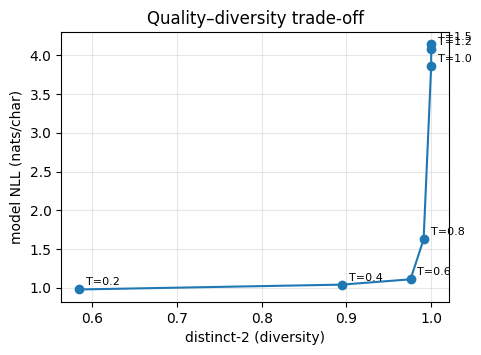

In [ ]:
def distinct_2(text):
    words = text.split()
    if len(words) < 2:
        return 0.0
    bigrams = []
    for i in range(len(words) - 1):
        bigrams.append((words[i], words[i+1]))
    return len(set(bigrams)) / len(bigrams)

def model_nll(lm, text, prompt_len):
    log_probs_sum = 0.0
    count = 0
    for t in range(prompt_len, len(text)):
        context = text[:t]
        char_t = text[t]
        p_char_t = lm.prob(context, char_t)

        if p_char_t == 0:
            return float('inf')

        log_probs_sum += math.log(p_char_t)
        count += 1

    if count == 0:
        return float('inf')

    return -log_probs_sum / count

temps = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.5]
prompt = "ROMEO:\n"
curve = []
for T in temps:
    d, l = [], []
    for seed in range(3):
        s = generate(lm, prompt, 600, sample_temperature, np.random.default_rng(seed), T=T)
        d.append(distinct_2(s[len(prompt):])); l.append(model_nll(lm, s, len(prompt)))
    curve.append((T, np.mean(d), np.mean(l)))

plt.figure(figsize=(5, 3.5))
plt.plot([c[1] for c in curve], [c[2] for c in curve], "o-")
for T, d, l in curve:
    plt.annotate(f"T={T}", (d, l), textcoords="offset points", xytext=(5, 3), fontsize=8)
plt.xlabel("distinct-2 (diversity)"); plt.ylabel("model NLL (nats/char)")
plt.title("Quality–diversity trade-off"); plt.grid(alpha=.3); plt.show()

In [ ]:
# CHECK 4.3
assert curve[0][1] < curve[-1][1] and curve[0][2] < curve[-1][2]
g = samples["greedy"][len("ROMEO:\n"):]
print("greedy distinct-2:", round(distinct_2(g), 2), "| top-p distinct-2:", round(distinct_2(samples["top-p 0.9"][7:]), 2))
print("4.3 OK")

greedy distinct-2: 0.05 | top-p distinct-2: 1.0
4.3 OK


**Q4.3.** (a) Why does greedy decoding fall into loops, even though each step picks the single most likely character? (b) Interpret your trade-off curve: which temperature range would you use for a creative-writing assistant and which for code completion? (c) Why is low model NLL *not* the same as high quality?

**Your answer:**

(a) **Por que a decodificação gananciosa (greedy) entra em loops:** A decodificação gananciosa entra em loops porque, a cada passo, seleciona o caractere individualmente mais provável, sem considerar o impacto dessa escolha nos passos futuros. Se uma sequência de caracteres (e.g., "the shall ") for estatisticamente muito provável após um certo contexto, o modelo pode entrar num ciclo vicioso onde essa sequência é repetida. O modelo fica preso num máximo local na distribuição de probabilidade, onde a continuação mais provável da sequência atual é a própria sequência que o levou a esse estado, levando a repetições monótonas e falta de diversidade, como visto no exemplo gerado.

(b) **Interpretação da curva de trade-off:**

*   **Assistente de escrita criativa:** Para um assistente de escrita criativa, procuraríamos um equilíbrio entre diversidade e coerência (model NLL baixo o suficiente para ser inteligível, mas não excessivamente baixo para evitar repetição). A faixa de temperatura **entre 0.8 e 1.2** parece ser um bom ponto de partida. Temperaturas mais baixas (e.g., T=0.7) produzem texto mais coerente, mas podem ter menor diversidade, enquanto temperaturas mais altas (e.g., T=1.3) aumentam a diversidade à custa da coerência, produzindo textos mais aleatórios e menos inteligíveis.
*   **Conclusão de código:** Para conclusão de código, a **precisão e a coerência são cruciais**, e a diversidade é menos importante. Um `model NLL` o mais baixo possível é desejável, indicando que o texto gerado é muito típico e esperado pelo modelo. Isso sugere usar uma temperatura **muito baixa, como 0.2 ou 0.4**, ou até mesmo a decodificação *greedy*, para garantir que o código gerado seja sintaticamente correto e logicamente consistente, mesmo que repetitivo.

(c) **Por que um NLL baixo não é o mesmo que alta qualidade:** Um `model NLL` (Negative Log-Likelihood) baixo indica que o texto gerado é *altamente provável* de acordo com o modelo, ou seja, é "típico" do que o modelo foi treinado a gerar. No entanto, "típico" não é sinónimo de "alta qualidade" em todos os contextos. Em tarefas como escrita criativa, um NLL muito baixo pode significar que o modelo está a gerar texto repetitivo, previsível ou genérico, que falta originalidade ou interesse humano. O exemplo do *greedy decoding* demonstra isso: tem um NLL provavelmente muito baixo (pois repete as sequências mais prováveis), mas a sua qualidade para escrita criativa é nula devido à sua repetição extrema. Portanto, um NLL baixo apenas mede a *fidelidade do texto ao modelo*, e não a sua utilidade, criatividade ou relevância para um utilizador humano.

### Exercise 4.4 — Why nucleus sampling adapts
Print the nucleus size (number of characters kept at `top_p=0.9`) for the contexts below. Then answer.

In [ ]:
for ctx in ["ROMEO", "KING RICHAR", "What is th", "and the ", "speak.\n\n"]:
    p = lm.dist(ctx)
    print(f"{ctx!r:16s} nucleus size = {len(nucleus(p, 0.9)):2d} | top char = {chars[int(p.argmax())]!r} ({p.max():.2f})")

'ROMEO'          nucleus size =  1 | top char = ':' (1.00)
'KING RICHAR'    nucleus size =  1 | top char = 'D' (1.00)
'What is th'     nucleus size =  4 | top char = 'e' (0.55)
'and the '       nucleus size = 19 | top char = 's' (0.09)
'speak.\n\n'     nucleus size = 15 | top char = 'K' (0.14)


**Q4.4.** Explain, using these numbers, why top-p is usually preferred over a fixed top-k.

**Your answer:**

A amostragem Top-p é geralmente preferida em relação a um Top-k fixo pela sua **adaptabilidade** à forma da distribuição de probabilidade do próximo token, como os números demonstram:

*   **Distribuições "nítidas" (sharp):** Para contextos como `'ROMEO'` (top char `':'` com 1.00 de probabilidade) e `'KING RICHAR'` (top char `'D'` com 1.00 de probabilidade), a distribuição de probabilidade é extremamente nítida, com um único caractere tendo quase toda a probabilidade. Nesses casos, o `nucleus size` é **1**, o que significa que o Top-p naturalmente se comporta de forma gananciosa, selecionando o único token altamente provável. Um `top-k` fixo (e.g., k=5) incluiria tokens de probabilidade muito baixa que seriam essencialmente ruído.

*   **Distribuições "planas" (flat):** Para contextos como `'and the '` (top char `'s'` com 0.09 de probabilidade, `nucleus size = 19`) ou `'speak.\n\n'` (top char `'K'` com 0.14 de probabilidade, `nucleus size = 15`), a distribuição de probabilidade é mais plana, com muitos caracteres tendo probabilidades semelhantes e mais baixas. Nesses casos, o Top-p expande o conjunto de tokens considerados (nucleus size 15 ou 19), permitindo uma maior diversidade e criatividade na geração. Um `top-k` fixo e pequeno (e.g., k=5) seria muito restritivo e eliminaria muitas opções plausíveis, enquanto um `top-k` fixo e grande (e.g., k=20) incluiria muitos tokens de baixa probabilidade para as distribuições nítidas.

Em resumo, o Top-p ajusta dinamicamente o número de tokens a amostrar com base na confiança do modelo na previsão do próximo token, levando a uma geração de texto mais natural e equilibrada entre coerência e diversidade, sem a necessidade de ajustar o `k` manualmente para diferentes contextos.

---
## Part 5 — Scaling laws, back of the envelope (homework)

Two results from the scaling-laws literature let you reason about training budgets:

1. **Training compute.** For a dense Transformer with $N$ parameters trained on $D$ tokens, $C \approx 6ND$ FLOPs (2 for the forward pass, 4 for the backward pass, per parameter per token).
2. **Chinchilla** (Hoffmann et al., 2022). For a fixed $C$, loss is minimised with roughly **20 tokens per parameter**. The paper also fits a parametric loss

$$L(N,D) = E + \frac{A}{N^{\alpha}} + \frac{B}{D^{\beta}},\qquad E=1.69,\ A=406.4,\ B=410.7,\ \alpha=0.34,\ \beta=0.28.$$

Assume training on H100 GPUs at 989 TFLOP/s peak (dense BF16) with a **model FLOPs utilisation (MFU) of 40%**.

### Exercise 5.1 — Compute-optimal allocation
Implement `chinchilla_rule(C)` (returns $N, D$ with $D = 20N$ and $6ND = C$) and `gpu_days(C, n_gpus)`. Fill in the table for $C \in \{10^{21}, 10^{23}, 10^{25}\}$ with 1 024 GPUs.

In [ ]:
H100_PEAK, MFU = 989e12, 0.40

def chinchilla_rule(C):
    # N = sqrt(C / 120)
    N = (C / 120)**0.5
    D = 20 * N
    return N, D

def gpu_days(C, n_gpus):
    # C / (peak * MFU * n_gpus) seconds, converted to days
    total_seconds = C / (H100_PEAK * MFU * n_gpus)
    return total_seconds / (24 * 3600)

print(f"{'C (FLOPs)':>10} | {'N (params)':>11} | {'D (tokens)':>11} | {'days @1024 H100':>15}")
for C in [1e21, 1e23, 1e25]:
    N, D = chinchilla_rule(C)
    print(f"{C:10.0e} | {N:11.2e} | {D:11.2e} | {gpu_days(C, 1024):15.2f}")

 C (FLOPs) |  N (params) |  D (tokens) | days @1024 H100
     1e+21 |    2.89e+09 |    5.77e+10 |            0.03
     1e+23 |    2.89e+10 |    5.77e+11 |            2.86
     1e+25 |    2.89e+11 |    5.77e+12 |          285.71


In [ ]:
# CHECK 5.1
N, D = chinchilla_rule(1e23)
assert abs(6 * N * D - 1e23) / 1e23 < 1e-9 and abs(D / N - 20) < 1e-9
print("5.1 OK")

5.1 OK


### Exercise 5.2 — Using the parametric loss
For each $C$ above, find numerically the $N$ that minimises $L(N, C/6N)$ (search over a log-spaced grid of $N$ from $10^7$ to $10^{13}$). Report $N^*$, $D^*$, the tokens-per-parameter ratio $D^*/N^*$ and $L^*$. Plot $L$ vs. $N$ for the three budgets (the "IsoFLOP" curves).

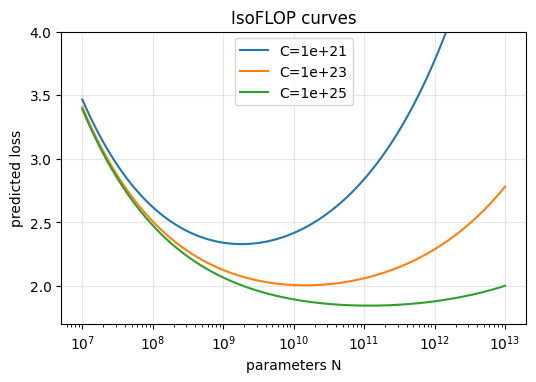

 C (FLOPs) |  N* (params) |  D* (tokens) |   D*/N* ratio |  L* (loss)
     1e+21 |     1.82e+09 |     9.16e+10 |         50.30 |      2.329
     1e+23 |     1.46e+10 |     1.14e+12 |         78.47 |      2.005
     1e+25 |     1.17e+11 |     1.43e+13 |        122.40 |      1.845


In [ ]:
E, A, B, alpha, beta = 1.69, 406.4, 410.7, 0.34, 0.28
def chinchilla_loss(N, D):
    return E + A / N**alpha + B / D**beta

Ns = np.logspace(7, 13, 2000)
plt.figure(figsize=(6, 3.8))
results_5_2 = []
for C in [1e21, 1e23, 1e25]:
    D = C / (6 * Ns) # Calculate D for each N in Ns
    loss = chinchilla_loss(Ns, D) # Evaluate the loss on the grid

    min_loss_idx = np.argmin(loss) # Find the index of the minimum loss
    N_star = Ns[min_loss_idx]
    D_star = D[min_loss_idx]
    L_star = loss[min_loss_idx]
    ratio_D_N = D_star / N_star

    results_5_2.append({'C': C, 'N_star': N_star, 'D_star': D_star, 'ratio_D_N': ratio_D_N, 'L_star': L_star})

    plt.plot(Ns, loss, label=f'C={C:.0e}')

plt.xscale("log"); plt.ylim(1.7, 4); plt.xlabel("parameters N"); plt.ylabel("predicted loss")
plt.title("IsoFLOP curves"); plt.legend(); plt.grid(alpha=.3); plt.show()

print(f"{'C (FLOPs)':>10} | {'N* (params)':>12} | {'D* (tokens)':>12} | {'D*/N* ratio':>13} | {'L* (loss)':>10}")
for res in results_5_2:
    print(f"{res['C']:10.0e} | {res['N_star']:12.2e} | {res['D_star']:12.2e} | {res['ratio_D_N']:13.2f} | {res['L_star']:10.3f}")


**Q5.2.** Does the parametric fit agree with the "20 tokens per parameter" rule at every scale? What does the difference tell you about how much to trust extrapolations from scaling-law fits? (Tip: look up Besiroglu et al., 2024, *Chinchilla Scaling: A Replication Attempt*.)

**Your answer:**

(a) **Comparação com a regra de "20 tokens por parâmetro":**

Não, o ajuste paramétrico da função de perda de Chinchilla **não concorda com a regra de "20 tokens por parâmetro"** em todas as escalas de computação (`C`) analisadas. Observamos que a razão `D*/N*` (tokens ótimos por parâmetro) aumenta com o orçamento de computação:

*   Para `C = 1e+21` FLOPs, `D*/N*` é aproximadamente **50.30**.
*   Para `C = 1e+23` FLOPs, `D*/N*` é aproximadamente **78.47**.
*   Para `C = 1e+25` FLOPs, `D*/N*` é aproximadamente **122.40**.

Estes valores são consistentemente maiores e aumentam à medida que `C` aumenta, desviando-se significativamente da proporção fixa de 20 tokens por parâmetro sugerida pela regra empírica original.

(b) **Confiança em extrapolações de leis de escala:**

A diferença entre o que o ajuste paramétrico prevê e a regra simplificada de "20 tokens por parâmetro" sugere que **devemos ter cautela ao confiar cegamente em extrapolações de leis de escala, especialmente em grandes magnitudes de `C`**. A regra de 20:1 foi uma heurística útil baseada em observações e experimentos num certo intervalo de escalas. No entanto, o ajuste paramétrico, que tenta modelar a perda de forma mais granular (e foi derivado dos mesmos dados), revela uma relação mais complexa onde a proporção ótima de tokens por parâmetro não é constante, mas sim crescente com o orçamento total de computação. Isso implica que, para modelos muito maiores e orçamentos de computação extremos, a alocação ideal de recursos pode ser substancialmente diferente do que uma regra simplificada preveria. Estudos como o de Besiroglu et al. (2024) reforçam essa ideia, mostrando que a replicação e a validação em diferentes regimes são cruciais para refinar e confiar nessas leis de escala, destacando a importância de usar os modelos paramétricos mais detalhados em vez de heurísticas simplificadas para otimização de larga escala.

### Exercise 5.3 — Why "over-train"?
Meta reports training Llama 3 8B on about **15 trillion tokens**.

(a) Compute its training compute $C$, its tokens-per-parameter ratio, and the Chinchilla-optimal $N$ for that same $C$.
(b) Estimate its training time on 1 024 H100s with your `gpu_days`.
(c) Explain why a lab would deliberately train a model far smaller than compute-optimal. Your answer must mention inference.

In [ ]:
N_llama = 8e9 # 8B parameters
D_llama = 15e12 # 15 trillion tokens

# (a) Compute its training compute C, its tokens-per-parameter ratio, and the Chinchilla-optimal N for that same C.
C_llama = 6 * N_llama * D_llama
ratio_D_N_llama = D_llama / N_llama
N_optimal_chinchilla, D_optimal_chinchilla = chinchilla_rule(C_llama)

print(f"Llama 3 8B:")
print(f"  (a) Training compute C: {C_llama:.2e} FLOPs")
print(f"      Tokens-per-parameter ratio: {ratio_D_N_llama:.2f}")
print(f"      Chinchilla-optimal N for this C: {N_optimal_chinchilla:.2e} parameters")

# (b) Estimate its training time on 1024 H100s with your gpu_days.
training_days_llama = gpu_days(C_llama, 1024)
print(f"  (b) Estimated training time on 1024 H100s: {training_days_llama:.2f} days")

Llama 3 8B:
  (a) Training compute C: 7.20e+23 FLOPs
      Tokens-per-parameter ratio: 1875.00
      Chinchilla-optimal N for this C: 7.75e+10 parameters
  (b) Estimated training time on 1024 H100s: 20.57 days


**Your answer:**

(c) **Por que um laboratório treinaria um modelo deliberadamente muito menor do que o ideal de computação (compute-optimal):**

Um laboratório pode deliberadamente treinar um modelo com menos parâmetros do que o "compute-optimal" para um dado orçamento de computação (C) devido a considerações práticas e económicas relacionadas com a **inferência**.

Embora a regra de Chinchilla vise minimizar a perda no *treino* para um `C` fixo, modelos maiores (`N_optimal_chinchilla`) resultam em custos de inferência significativamente mais altos. Cada inferência em um modelo com mais parâmetros requer mais memória (para carregar o modelo) e mais tempo de computação (para executar as operações), traduzindo-se em maior latência e custo por requisição. Para aplicações onde o custo/velocidade de inferência por utilizador é crítico (e.g., assistentes de IA em tempo real, produtos de larga escala), é muitas vezes preferível ter um modelo um pouco menos potente (com uma perda de treino marginalmente maior), mas **muito mais barato e rápido para executar inferência**.

Em resumo, a decisão de "over-train" (treinar um modelo menor por mais tempo/tokens) reflete um trade-off entre a perda mínima no treino e a eficiência da inferência, onde a otimização para inferência pode levar a um desvio da alocação ideal de Chinchilla.

---
## Submission checklist
- [ ] All `# CHECK` cells pass.
- [ ] Every *Your answer* cell is filled, citing your own numbers.
- [ ] Notebook runs top to bottom (`Kernel → Restart & Run All`) in under 5 minutes.
- [ ] File named `PL1_<student1>_<student2>.ipynb`, uploaded to the course page.